In [186]:
from sympy import *
init_printing(use_latex=True)
from scipy.integrate import solve_ivp
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.offsetbox import AnchoredText

%matplotlib widget

In [165]:
t,r,theta,phi = symbols('t r theta phi', cls = Function)
td,rd,thetad,phid = symbols('td rd thetad phid', cls = Function)
lam = symbols('lam')
m = symbols('m', positive = True)

t = t(lam)
r = r(lam)
theta = theta(lam)
phi = phi(lam)

td = td(lam)
rd = rd(lam)
thetad = thetad(lam)
phid = phid(lam)

tdd = -(m/(r*(r - 2*m)) * td * rd)
rdd = -(m*(r-2*m)/r**3*td**2 - m/(r*(r-2*m))*rd**2 - 
          (r-2*m)*thetad**2 - (r-2*m)*sin(theta)**2*phid**2)
thetadd = -(2/r*thetad*thetad - sin(2*theta)/2*phid**2)
phidd =  -(2/r*rd*phid + 2*cot(theta)*thetad*phid)

#dsolve(Eq(geod_t,0), t)

In [166]:
m_val = 5

metric_t = -(1-2*m/r)
metric_r = 1/(1-2*m/r)
metric_theta = r**2
metric_phi = r**2*sin(theta)**2

metric = np.array([metric_t, metric_r, 
          metric_theta, metric_phi])

In [167]:
dd_m_sub = [e.subs(m,m_val) for e in [tdd,rdd,thetadd,phidd]]
g_m_sub = [e.subs(m,m_val) for e in metric]

f_dd = lambdify(
    (t,r,theta,phi,td,rd,thetad,phid),
    dd_m_sub,
    'numpy'
)

metric_lam = lambdify((r, theta), g_m_sub, 'numpy')

def null_curve(r_,th_, ders):
    g = np.array(metric_lam(r_,th_))
    v = np.array(ders)
    dt = np.sqrt(-(np.sum(g[1:]*v**2)/g[0]))
    return dt

def geod(lam,coord):

    [t,r,theta,phi] = coord[:4]
    v = coord[4:]
    return [ *v, *f_dd(*coord)]



    

In [199]:
[t0,r0,theta0,phi0] = [0,20,np.pi/2-0.5,np.pi/4]
[rd0,thetad0,phid0] = [-0.05,0,0.1]
td0 = null_curve(r0, theta0, [rd0,thetad0,phid0])

coord0 = [t0,r0,theta0,phi0,td0,rd0,thetad0,phid0]

lam0 = 0
lam_max = 100

sol = solve_ivp(
    geod,
    [lam0, lam_max],
    coord0
)

t_a,r_a,th_a,phi_a,td_a,rd_a,thd_a,phid_a = sol.y

print(sol)

x_a = r_a * np.cos(phi_a) * np.sin(th_a)
y_a = r_a * np.sin(phi_a) * np.sin(th_a)
z_a = r_a * np.cos(th_a)



  message: The solver successfully reached the end of the integration interval.
  success: True
   status: 0
        t: [ 0.000e+00  9.808e-04 ...  9.879e+01  1.000e+02]
        y: [[ 0.000e+00  2.436e-03 ...  1.984e+02  2.005e+02]
            [ 2.000e+01  2.000e+01 ...  2.241e+02  2.292e+02]
            ...
            [ 0.000e+00  4.126e-06 ... -1.318e-02 -1.319e-02]
            [ 1.000e-01  1.000e-01 ...  4.081e-03  3.612e-03]]
      sol: None
 t_events: None
 y_events: None
     nfev: 134
     njev: 0
      nlu: 0


<>:25: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:25: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
C:\Users\Francesco\AppData\Local\Temp\ipykernel_22292\1064341090.py:25: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
  f"$r_0={r0}$,  $\phi_0 = {np.round(phi0,2)}$, $\\theta_0={theta0:.2f}$\n$\\dot r_0={rd0}$, $\\dot\\phi_0={phid0}$, $\\dot\\theta_0 = {thetad0}$",


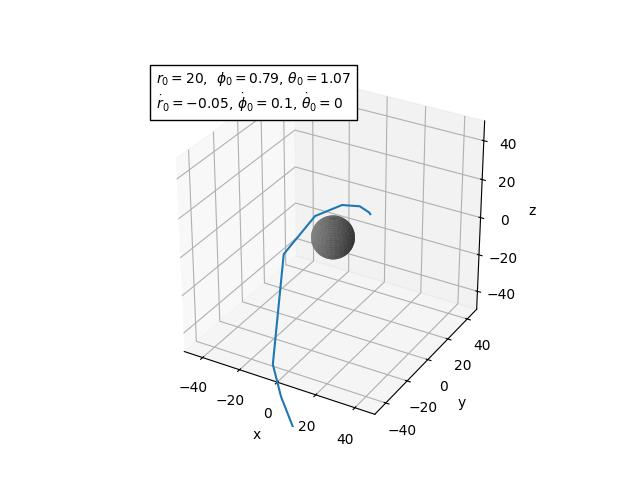

In [200]:
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.plot(x_a,y_a,z_a)
u,v = np.mgrid[0:2*np.pi:60j, 0:np.pi:30j]
R = 2*m_val

ax.plot_surface(
    R*np.cos(u)*np.sin(v),
    R*np.sin(u)*np.sin(v),
    R*np.cos(v),
    color = 'grey'
)

ax.set_xlim(-50,50)
ax.set_ylim(-50,50)
ax.set_zlim(-50,50)
ax.set_box_aspect((1,1,1))

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')


at = AnchoredText(
    f"$r_0={r0}$,  $\phi_0 = {np.round(phi0,2)}$, $\\theta_0={theta0:.2f}$\n$\\dot r_0={rd0}$, $\\dot\\phi_0={phid0}$, $\\dot\\theta_0 = {thetad0}$",
    loc='upper left',
    prop=dict(fontsize=10),
    frameon=True,
)
ax.add_artist(at)